# CSC14120 — Panorama Image Stitching
## Nhóm 22 · Báo cáo giữa kỳ — Phiên bản tuần tự V0 & Kế hoạch CUDA

| | |
|---|---|
| **Môn học** | CSC14120 – Lập trình song song |
| **Trọng số** | 10% tổng điểm đồ án |
| **Hạn nộp** | 23:59, cuối tuần thứ 7 |
| **Repository** | [github.com/HungHiHung10/Midterm-Parallel-Programming](https://github.com/HungHiHung10/Midterm-Parallel-Programming) |
| **Dataset** | [Google Drive — Nhóm 22](https://drive.google.com/drive/folders/1KEfstxQ1an5bEngfaHfXl9wIdbXWo2wF?usp=sharing) |

> **Ghi chú kỹ thuật:** Mọi số liệu, bảng biểu và hình ảnh trong báo cáo đều được sinh tự động từ output cell — không điền thủ công. Chương trình C++ biên dịch trực tiếp từ `src/`, tuân thủ nguyên tắc *"One source of truth"* theo yêu cầu đề bài.

---

## 0. Setup — Thiết lập môi trường

**Trên máy cục bộ (Local):** Mở notebook trong thư mục dự án chứa `src/`.

**Trên Google Colab:**
1. Giải nén `Group22_Midterm.zip` + `Group22_Dataset.zip` cùng vào `/content/Group22_Midterm`, hoặc
2. Đặt `src/`, `tools/`, `team.json`, `requirements.txt`, `dataset/` vào thư mục Drive được cấu hình trong cell bên dưới.

Cell setup sẽ tự động mount Drive, copy mã nguồn, cài dependencies và biên dịch chương trình.


In [1]:
from pathlib import Path
import os, sys, shutil, subprocess, json
IN_COLAB = 'google.colab' in sys.modules
DRIVE_PROJECT = '/content/drive/MyDrive/Group22_Midterm'  # sửa theo thư mục Drive thực tế
if IN_COLAB:
    ROOT = Path('/content/Group22_Midterm')
    if not (ROOT/'src').exists():
        from google.colab import drive
        drive.mount('/content/drive')
        source = Path(DRIVE_PROJECT)
        assert (source/'src').is_dir(), f'Chưa có src tại {source}; giải nén gói hoặc sửa DRIVE_PROJECT.'
        ROOT.mkdir(parents=True, exist_ok=True)
        for name in ['src', 'tools', 'dataset']:
            if (source/name).exists():
                shutil.copytree(source/name, ROOT/name, dirs_exist_ok=True)
        for name in ['team.json', 'requirements.txt']:
            shutil.copy2(source/name, ROOT/name)
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q',
                    'numpy', 'Pillow', 'pillow-heif', 'matplotlib'], check=True)
else:
    ROOT = Path.cwd().resolve()
assert (ROOT/'src/main.cu').exists(), 'Mở notebook tại thư mục chứa src/'
os.chdir(ROOT)
# Never import binary Python packages from a project-local vendor directory:
# compiled extensions such as Pillow's _imaging are interpreter-specific.
local_vendor = str(ROOT/'.tools')
while local_vendor in sys.path:
    sys.path.remove(local_vendor)
tools_path = str(ROOT/'tools')
if tools_path not in sys.path:
    sys.path.insert(0, tools_path)
from build import build
binary, build_command = build(ROOT)
print('Binary:', binary)
print('Build command:', ' '.join(build_command))
print('Compiler:', subprocess.check_output([build_command[0], '--version'], text=True).splitlines()[0])
(ROOT/'outputs_v0').mkdir(exist_ok=True)
team = json.loads((ROOT/'team.json').read_text(encoding='utf-8-sig'))


[PROCESS]: C:\msys64\ucrt64\bin\g++.EXE -O3 -std=c++14 -x c++ C:\VSC\HW\Midterm-Parallel-Programming\src\main.cu C:\VSC\HW\Midterm-Parallel-Programming\src\stb_impl.cpp C:\VSC\HW\Midterm-Parallel-Programming\src\v0_frontend.cpp C:\VSC\HW\Midterm-Parallel-Programming\src\v0_backend.cpp C:\VSC\HW\Midterm-Parallel-Programming\src\v0_stitching.cpp -o C:\VSC\HW\Midterm-Parallel-Programming\stitch.exe


Binary: C:\VSC\HW\Midterm-Parallel-Programming\stitch.exe
Build command: C:\msys64\ucrt64\bin\g++.EXE -O3 -std=c++14 -x c++ C:\VSC\HW\Midterm-Parallel-Programming\src\main.cu C:\VSC\HW\Midterm-Parallel-Programming\src\stb_impl.cpp C:\VSC\HW\Midterm-Parallel-Programming\src\v0_frontend.cpp C:\VSC\HW\Midterm-Parallel-Programming\src\v0_backend.cpp C:\VSC\HW\Midterm-Parallel-Programming\src\v0_stitching.cpp -o C:\VSC\HW\Midterm-Parallel-Programming\stitch.exe
Compiler: g++.EXE (Rev7, Built by MSYS2 project) 13.1.0


---

## 3.1 Thông tin nhóm và kế hoạch công việc

### Danh sách thành viên


In [2]:
from report import table
table(['Thành viên', 'Họ tên', 'MSSV', 'Trách nhiệm V0'], [
    [m['role'], m['name'], m['student_id'],
     {1:'Backend: stages 4–6', 2:'Frontend: stages 1–3', 3:'System, data, profiling, notebook'}[m['role']]]
    for m in team['members']])
if not team.get('role_order_confirmed'):
    from console import log
    log('WARN', 'Vai trò thành viên chưa được xác nhận đầy đủ.')


| Thành viên | Họ tên | MSSV | Trách nhiệm V0 |
|---|---|---|---|
| 3 | Nguyễn Hữu Khánh Hưng | 23120271 | System, data, profiling, notebook |
| 2 | Vũ Trần Phúc | 23120333 | Frontend: stages 1–3 |
| 1 | Trần Nguyễn Minh Quân | 23120342 | Backend: stages 4–6 |

### Lộ trình phân công từ V0 đến Final

| Mốc thời gian | TV1 — Back-end Lead | TV2 — Front-end Lead | TV3 — System Lead |
|:---|:---|:---|:---|
| **Midterm / V0** (Tuần 7) | Matching, RANSAC, Warp/Blend | Grayscale/Blur, FAST/NMS, BRIEF | CLI, Dataset, Correctness, Profiling, Notebook |
| **V1** (Tuần 8–9) | CUDA kernels Stages 4–6 | CUDA kernels Stages 1–3 | CUDA Events, đối chiếu V0 vs V1, đo truyền dữ liệu |
| **V2** (Tuần 10) | Tiling Matching, Parallel RANSAC | Shared-memory Blur, Scan/Compaction | Nsight profiling: throughput, occupancy |
| **V3** (Tuần 11) | Texture Sampling, Blending | Hai stream frontend (ảnh A ∥ B) | Kernel Fusion, Pinned Memory |
| **Final** (Tuần 12–13) | Slide & demo (Stages 4–6) | Slide & demo (Stages 1–3) | Tổng hợp báo cáo, đóng gói, video |


---

## 3.2 Hiểu bài toán — Pipeline ghép ảnh 6 giai đoạn

```
[Ảnh A] ─→ Stage 1 ─→ Stage 2 ─→ Stage 3 ─┐
                                              ├─→ Stage 4 ─→ Stage 5 ─→ Stage 6 ─→ [Panorama]
[Ảnh B] ─→ Stage 1 ─→ Stage 2 ─→ Stage 3 ─┘
```

Hai ảnh A (left) và B (right) đi qua ba giai đoạn xử lý ảnh độc lập (Stages 1–3), sau đó hội tụ tại giai đoạn so khớp (Stage 4) để tìm mối tương quan, ước lượng phép biến đổi hình học (Stage 5) và ghép thành ảnh toàn cảnh (Stage 6).

| Stage | Tên gọi | Mô tả |
|:---:|:---|:---|
| **1** | **Preprocessing** | Chuyển RGB → Grayscale (Rec. 601); Gaussian Blur 5×5 tách rời để giảm nhiễu |
| **2** | **Keypoint Detection** | FAST-9 phát hiện góc → NMS 3×3 loại dồn cục → Top-K giữ điểm mạnh nhất |
| **3** | **Feature Description** | BRIEF 256-bit — sinh vector nhị phân mô tả vùng lân cận 31×31 quanh keypoint |
| **4** | **Feature Matching** | Brute-Force Hamming + Lowe's ratio test + Mutual nearest neighbor |
| **5** | **Homography Estimation** | RANSAC + DLT → ma trận $H_{3 \times 3}$ ánh xạ B → A; refit trên inliers |
| **6** | **Warping & Blending** | Inverse Warping + Bilinear Interpolation + bù phơi sáng + feather/seam blending |

**Giả định mô hình:** Homography phù hợp khi cảnh gần phẳng hoặc máy ảnh xoay quanh tâm chiếu. Vật thể ở nhiều độ sâu khác nhau hoặc chuyển động có thể gây bóng kép (ghosting). Stage 6 bổ sung bù phơi sáng affine (khi giảm ≥ 10% MAE vùng chồng lấp) và adaptive seam để giảm artefact.

---

## 3.3 Phương pháp và tham số lựa chọn

> Mỗi phương pháp được lựa chọn dựa trên hai tiêu chí: **(1) Chất lượng đầu ra** và **(2) Tính phù hợp để song song hóa trên GPU**.

| Stage | Cài đặt V0 & Tham số | Chất lượng / Hướng GPU |
|:---:|:---|:---|
| **1** | Rec. 601 ($Y = 0.299R + 0.587G + 0.114B$); Gaussian tách rời $5 \times 5$, $\sigma = 1.2$; biên clamp | Giảm nhiễu hiệu quả; mỗi pixel xử lý độc lập → grid 2D trên GPU |
| **2** | FAST-9, threshold = 20; kiểm tra sớm 2/4 điểm la bàn; NMS $3 \times 3$; Top-K = 1500; biên loại trừ 16 px | Giới hạn chi phí matching; Top-K chưa bảo đảm phân bố đều; GPU cần Scan/Compaction riêng |
| **3** | BRIEF 256-bit (32 byte); patch $31 \times 31$; Gaussian $\sigma = 6$; seed = 14120 | Nhỏ gọn, mọi keypoint đều có descriptor hợp lệ; chưa bất biến xoay/tỷ lệ |
| **4** | BF Hamming, ratio < 0.75, mutual nearest A↔B | Loại match mơ hồ/lặp; hai lượt quét → dự kiến tiling + `__popc()` trên GPU |
| **5** | RANSAC 1500 iter, seed = 42; symmetric error < 3 px; DLT chuẩn hóa 8 tham số; refit 2 lượt; tối thiểu 8 inlier và 20% | Ổn định theo phân giải; có thể song song mỗi giả thuyết trên 1 block |
| **6** | Inverse warp + bilinear; bù sáng affine có kiểm chứng; adaptive seam hoặc distance feather | Giảm vệt sáng/ghosting; estimation/seam cần reduction/DP ngoài kernel pixel |

**Giới hạn V0 đã biết:** BRIEF chưa có pyramid/orientation → nhạy xoay/tỷ lệ; Top-K chưa chia lưới → phân bố không đều; global homography gây projective skew khi cảnh không phẳng. Bù sáng/seam giảm artefact nhưng không phục hồi hình học sai do parallax.

---

## 3.4 Kiến trúc phiên bản tuần tự V0

### Tổ chức mã nguồn

```
src/
├── common.h          Struct: ImageRGB, ImageGray, Keypoint, Descriptor256, Match, Homography3x3, StageTimings
├── versions.h        Giao diện: run_v0(...)
├── main.cu           CLI Driver — parse argv, nạp ảnh, gọi run_v0, benchmark, lưu output
├── stb_impl.cpp      Tích hợp stb_image / stb_image_write
├── v0_frontend.cpp   [TV2] Stages 1–3: rgb2gray, gaussian_blur, fast_detect, nms_topk, brief_compute
├── v0_backend.cpp    [TV1] Stages 4–6: brute_force_hamming, ransac_homography, inverse_warp_blend
├── v0_stitching.cpp  [TV3] Hàm run_v0(...) — kết nối 6 stage thành pipeline hoàn chỉnh
├── cuda_utils.cuh    CHECK_CUDA macro + GpuTimer (chuẩn bị cho V1, chưa dùng ở V0)
└── logging.h         Log có màu: SUCCESS/ERROR/WARN/PROCESS (NO_COLOR tắt ANSI)
```

### Đặc điểm thiết kế

| Thuộc tính | Chi tiết |
|:---|:---|
| **Luồng thực thi** | Đơn luồng, không OpenMP / `std::thread` / SIMD tự viết |
| **Đo thời gian** | `std::chrono::high_resolution_clock` bọc từng stage; I/O đĩa nằm ngoài vùng đo |
| **Warmup** | 1 lần khởi động bị loại; thống kê dùng 5 lần đo tiếp theo |
| **Total** | Đo toàn pipeline (bao gồm điều phối/cấp phát nội bộ); min total ≠ tổng min stage |
| **Homography** | $H$: B → A (ánh xạ right sang left) |

### Trích dẫn nguồn mã mở

| Thư viện / Tài liệu | Nguồn | Giấy phép |
|:---|:---|:---|
| `stb_image.h`, `stb_image_write.h` | Sean Barrett — [nothings/stb](https://github.com/nothings/stb) | MIT / Public Domain |
| FAST detector | Rosten & Drummond, 2006 | Tham khảo thuật toán |
| BRIEF descriptor | Calonder et al., 2010 | Tham khảo thuật toán |
| Lowe's ratio test | D. Lowe, 2004 | Tham khảo thuật toán |
| RANSAC | Fischler & Bolles, 1981 | Tham khảo thuật toán |
| DLT / Homography | Hartley & Zisserman, 2003 | Tham khảo thuật toán |

Các tiện ích hệ thống (logging, build, benchmark) do nhóm tự viết. TV1/TV2 cần xác nhận nếu module frontend/backend có tái sử dụng mã từ nguồn khác ngoài danh sách trên.


---

## 3.5 Kết quả V0 và Profiling

### Chuẩn bị dữ liệu & Chạy thí nghiệm

- **Synthetic pair:** Giữ nguyên cặp đã cung cấp nếu có. Khi chưa có, sinh fixture dịch chuyển xác định (320 px, seed cố định) để kiểm tra tích hợp pipeline. Fixture này **không thay thế** synthetic pair chính thức nếu môn học yêu cầu.
- **Metadata & chiều H:** Lưu trong `provenance.json` kèm thông tin nguồn gốc.
- **Benchmark:** 5 measured runs + 1 warmup, 4 sites × 3 độ phân giải.


In [3]:
from prepare_dataset import prepare, synthetic
expected = [ROOT/f'dataset/prepared/{res}/{site}_{side}.png'
            for res in ['small','medium','large']
            for site in ['site1_indoor','site2_outdoor','site3_custom','site4_challenging']
            for side in ['left','right']]
if not all(path.exists() for path in expected) or not (ROOT/'dataset/prepared/manifest.json').exists():
    prepare(ROOT)
required_synthetic = ['synthetic_left.png','synthetic_right.png','H_ground_truth.txt']
if not all((ROOT/'dataset/synthetic'/name).exists() for name in required_synthetic):
    print('[WARN]: Chưa có synthetic chính thức; dùng fixture tự sinh và ghi rõ provenance.')
    synthetic(ROOT)
from benchmark import benchmark
summary = benchmark(ROOT, runs=5, warmup=1)
summary['build_command'] = build_command
summary['compiler_version'] = subprocess.check_output([build_command[0], '--version'], text=True).splitlines()[0]
(ROOT/'outputs_v0/summary.json').write_text(json.dumps(summary, indent=2), encoding='utf-8')
print('Machine:', summary['machine'], summary['processor'])
print('Measured at UTC:', summary['timestamp_utc'])
assert all(row['success'] for row in summary['results']), 'Có cặp thất bại; xem log trong outputs_v0/'


[PROCESS]: Benchmark small/site1_indoor
[PROCESS]: Benchmark small/site2_outdoor
[PROCESS]: Benchmark small/site3_custom
[PROCESS]: Benchmark small/site4_challenging
[PROCESS]: Benchmark medium/site1_indoor
[PROCESS]: Benchmark medium/site2_outdoor
[PROCESS]: Benchmark medium/site3_custom
[PROCESS]: Benchmark medium/site4_challenging
[PROCESS]: Benchmark large/site1_indoor
[PROCESS]: Benchmark large/site2_outdoor
[PROCESS]: Benchmark large/site3_custom
[PROCESS]: Benchmark large/site4_challenging
[SUCCESS]: 12/12 successful real pairs
Machine: Windows-11-10.0.26200-SP0 AMD64 Family 25 Model 80 Stepping 0, AuthenticAMD
Measured at UTC: 2026-10-24T12:41:51.749501+00:00


### 3.5.1 Đánh giá tính đúng đắn (Correctness)

**Phương pháp đo:**
- Chuẩn hóa $H$ theo phần tử $[2,2]$.
- **Frobenius norm:** $\| H_{est} - H_{gt} \|_F$ — đo sai lệch tổng thể ma trận.
- **Mean projection error:** Chiếu lưới điểm ảnh B qua $H_{est}$ và $H_{gt}$, tính khoảng cách Euclidean trung bình.

**Ngưỡng nội bộ:** Mean projection error < 1 px (tiêu chí kiểm thử tích hợp, không phải yêu cầu từ đề bài). Kiểm thử dịch chuyển thuần không chứng minh tính đúng với phép biến đổi phối cảnh tổng quát.


In [4]:
from report import show_correctness
show_correctness(summary)

**Synthetic provenance:** local_generated_translation_fixture

H estimated (B -> A):
 [[ 1.00057645e+00  1.21441032e-04  3.19992705e+02]
 [ 1.93386659e-04  1.00028117e+00 -3.71280193e-02]
 [ 9.75998069e-07  3.34724327e-07  1.00000000e+00]]
H ground truth (B -> A):
 [[  1.   0. 320.]
 [  0.   1.   0.]
 [  0.   0.   1.]]


| Metric | Measured value |
|---|---|
| Frobenius norm (H normalized by H[2,2]) | 3.784401e-02 |
| Mean projection error (px) | 8.644198e-02 |
| Max projection error (px) | 3.349441e-01 |
| Pass threshold (mean px) | 1.0 |
| Passed | True |

### 3.5.2 Panorama — Kết quả ghép ảnh cho từng địa điểm

Ảnh panorama được tạo ở **độ phân giải Medium (1920×1080)** — mỗi site 1 ảnh đầu ra.

| Đầu ra | Mô tả |
|:---|:---|
| `panorama_<site>.png` | Canvas đầy đủ — giữ toàn bộ footprint để kiểm tra |
| `panorama_<site>_cropped.png` | Crop hình chữ nhật lớn nhất không chứa nền đen — chỉ để trình bày |

> **Lưu ý:** Crop là hậu xử lý trình bày, nằm ngoài timing 6 stage, không sửa méo phối cảnh, đường nối hay bóng kép. Cảnh cây xanh (site 4) có cấu trúc lặp; ảnh indoor (site 1) có vùng ít texture và chênh sáng mạnh ở cửa sổ.


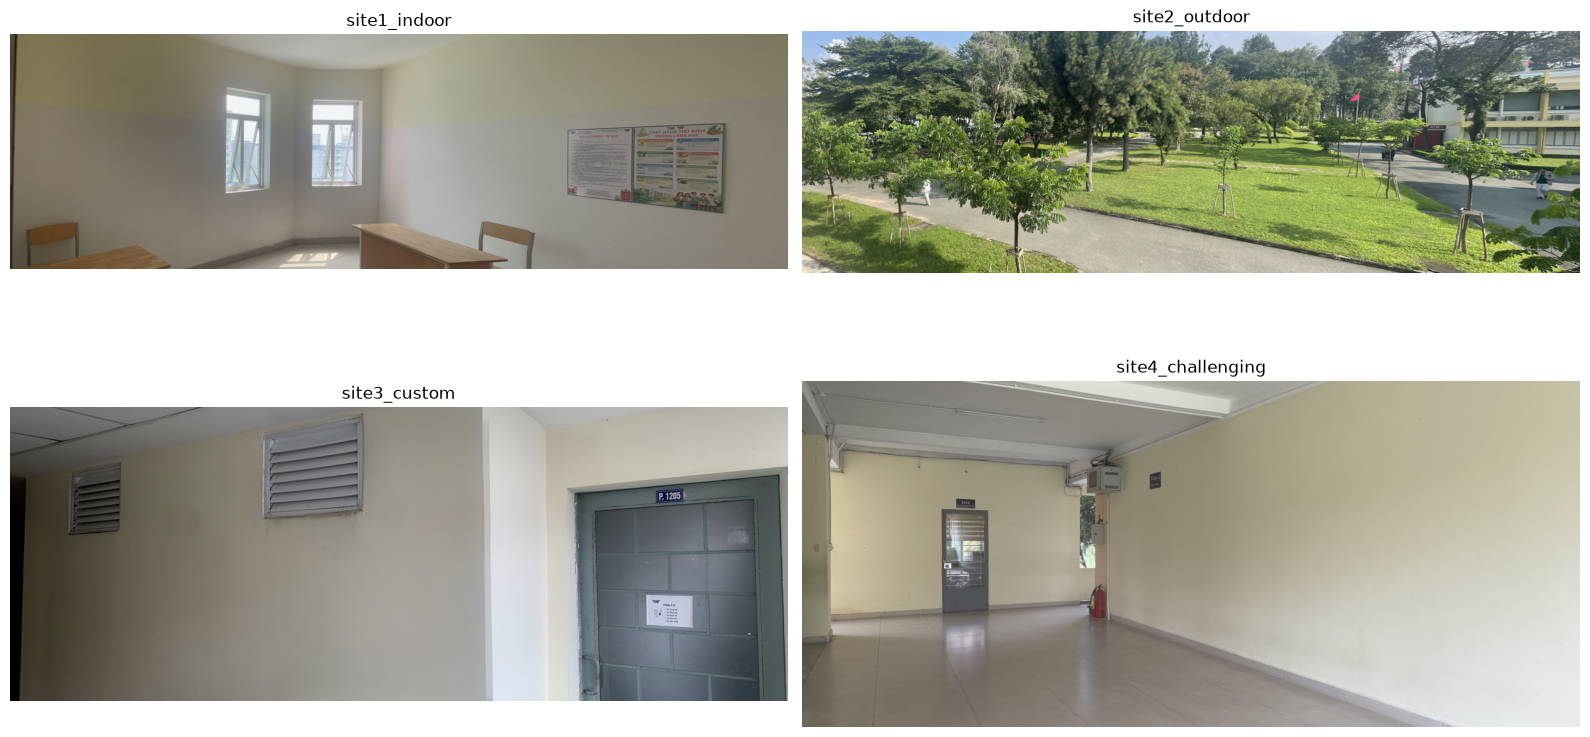

| Site | Exposure | Overlap MAE | Blend | Canvas retained |
|---|---|---|---|---|
| site1_indoor | affine | 6.595 | feather | 52.8% |
| site2_outdoor | unchanged | 22.330 | optimal | 57.6% |
| site3_custom | affine | 9.051 | feather | 65.1% |
| site4_challenging | affine | 3.824 | feather | 82.0% |

Overlap MAE dùng để chọn chiến lược trong từng cặp, không phải thước đo so sánh chất lượng giữa các cảnh có nội dung khác nhau.

Bản trên được crop theo hình chữ nhật lớn nhất không chứa nền canvas đen. Các file `panorama_<site>.png` vẫn giữ toàn bộ footprint để kiểm tra thuật toán.

In [5]:
from report import show_panoramas
show_panoramas(ROOT, summary)

### 3.5.3 Bảng thời gian và Performance Scaling

**Cấu trúc bảng:**
- **Bảng chi tiết:** Mean / Min riêng từng site × từng độ phân giải.
- **Bảng tổng hợp:** Trung bình đều 4 sites; cột `mean(site min)` = trung bình các giá trị min theo site (không phải min toàn bộ thí nghiệm).

**Biểu đồ:** Thời gian trung bình 4 sites, chia theo stage và độ phân giải. Kích thước ảnh đầu ra có thể khác nhau tùy $H$.

> *Dữ liệu thô đầy đủ từng lần đo được lưu trong CSV — xem `outputs_v0/`.*


| Resolution | Site | Stage | Mean ms | Min ms |
|---|---|---|---|---|
| small | site1_indoor | 1 Preprocess | 12.597 | 12.369 |
| small | site1_indoor | 2 Keypoints | 12.529 | 12.327 |
| small | site1_indoor | 3 BRIEF | 0.522 | 0.504 |
| small | site1_indoor | 4 Matching | 9.756 | 9.643 |
| small | site1_indoor | 5 RANSAC | 2.131 | 2.047 |
| small | site1_indoor | 6 Warp/blend | 68.790 | 68.142 |
| small | site1_indoor | Total | 106.354 | 105.742 |
| small | site2_outdoor | 1 Preprocess | 12.825 | 12.380 |
| small | site2_outdoor | 2 Keypoints | 144.083 | 142.917 |
| small | site2_outdoor | 3 BRIEF | 4.708 | 4.610 |
| small | site2_outdoor | 4 Matching | 1057.113 | 1049.931 |
| small | site2_outdoor | 5 RANSAC | 7.420 | 7.256 |
| small | site2_outdoor | 6 Warp/blend | 87.591 | 86.856 |
| small | site2_outdoor | Total | 1313.773 | 1306.595 |
| small | site3_custom | 1 Preprocess | 12.383 | 12.288 |
| small | site3_custom | 2 Keypoints | 10.924 | 10.653 |
| small | site3_custom | 3 BRIEF | 0.303 | 0.293 |
| small | site3_custom | 4 Matching | 2.494 | 2.430 |
| small | site3_custom | 5 RANSAC | 1.256 | 1.236 |
| small | site3_custom | 6 Warp/blend | 58.286 | 57.882 |
| small | site3_custom | Total | 85.675 | 85.214 |
| small | site4_challenging | 1 Preprocess | 12.908 | 12.420 |
| small | site4_challenging | 2 Keypoints | 13.261 | 13.032 |
| small | site4_challenging | 3 BRIEF | 0.752 | 0.735 |
| small | site4_challenging | 4 Matching | 25.717 | 25.601 |
| small | site4_challenging | 5 RANSAC | 3.759 | 3.682 |
| small | site4_challenging | 6 Warp/blend | 49.599 | 48.862 |
| small | site4_challenging | Total | 106.026 | 105.282 |
| medium | site1_indoor | 1 Preprocess | 28.172 | 27.877 |
| medium | site1_indoor | 2 Keypoints | 25.349 | 25.131 |
| medium | site1_indoor | 3 BRIEF | 0.924 | 0.874 |
| medium | site1_indoor | 4 Matching | 24.813 | 24.518 |
| medium | site1_indoor | 5 RANSAC | 2.467 | 2.444 |
| medium | site1_indoor | 6 Warp/blend | 154.076 | 152.814 |
| medium | site1_indoor | Total | 235.833 | 233.936 |
| medium | site2_outdoor | 1 Preprocess | 28.083 | 27.875 |
| medium | site2_outdoor | 2 Keypoints | 372.439 | 369.652 |
| medium | site2_outdoor | 3 BRIEF | 5.062 | 4.956 |
| medium | site2_outdoor | 4 Matching | 1048.824 | 1045.793 |
| medium | site2_outdoor | 5 RANSAC | 5.587 | 5.413 |
| medium | site2_outdoor | 6 Warp/blend | 198.341 | 195.718 |
| medium | site2_outdoor | Total | 1658.381 | 1656.286 |
| medium | site3_custom | 1 Preprocess | 28.496 | 27.696 |
| medium | site3_custom | 2 Keypoints | 25.664 | 24.741 |
| medium | site3_custom | 3 BRIEF | 0.690 | 0.634 |
| medium | site3_custom | 4 Matching | 10.384 | 9.977 |
| medium | site3_custom | 5 RANSAC | 1.769 | 1.603 |
| medium | site3_custom | 6 Warp/blend | 129.202 | 127.704 |
| medium | site3_custom | Total | 196.242 | 192.958 |
| medium | site4_challenging | 1 Preprocess | 27.984 | 27.573 |
| medium | site4_challenging | 2 Keypoints | 29.188 | 28.755 |
| medium | site4_challenging | 3 BRIEF | 1.479 | 1.474 |
| medium | site4_challenging | 4 Matching | 95.726 | 94.528 |
| medium | site4_challenging | 5 RANSAC | 5.647 | 5.534 |
| medium | site4_challenging | 6 Warp/blend | 114.266 | 111.337 |
| medium | site4_challenging | Total | 274.326 | 270.068 |
| large | site1_indoor | 1 Preprocess | 111.992 | 110.921 |
| large | site1_indoor | 2 Keypoints | 97.939 | 96.839 |
| large | site1_indoor | 3 BRIEF | 2.271 | 2.239 |
| large | site1_indoor | 4 Matching | 114.350 | 113.243 |
| large | site1_indoor | 5 RANSAC | 2.871 | 2.828 |
| large | site1_indoor | 6 Warp/blend | 622.203 | 613.297 |
| large | site1_indoor | Total | 951.668 | 939.921 |
| large | site2_outdoor | 1 Preprocess | 123.094 | 113.131 |
| large | site2_outdoor | 2 Keypoints | 1883.236 | 1845.080 |
| large | site2_outdoor | 3 BRIEF | 6.116 | 5.819 |
| large | site2_outdoor | 4 Matching | 1044.449 | 1031.974 |
| large | site2_outdoor | 5 RANSAC | 3.559 | 3.411 |
| large | site2_outdoor | 6 Warp/blend | 816.727 | 791.174 |
| large | site2_outdoor | Total | 3877.222 | 3849.235 |
| large | site3_custom | 1 Preprocess | 116.081 | 110.258 |
| large | site3_custom | 2 Keypoints | 96.525 | 94.067 |
| large | site3_custom | 3 BRIEF | 2.090 | 1.944 |
| large | site3_custom | 4 Matching | 91.891 | 90.706 |
| large | site3_custom | 5 RANSAC | 2.530 | 2.463 |
| large | site3_custom | 6 Warp/blend | 522.246 | 519.215 |
| large | site3_custom | Total | 831.401 | 820.774 |
| large | site4_challenging | 1 Preprocess | 111.219 | 108.912 |
| large | site4_challenging | 2 Keypoints | 109.821 | 107.714 |
| large | site4_challenging | 3 BRIEF | 4.140 | 4.026 |
| large | site4_challenging | 4 Matching | 700.413 | 693.724 |
| large | site4_challenging | 5 RANSAC | 10.713 | 10.542 |
| large | site4_challenging | 6 Warp/blend | 441.726 | 435.105 |
| large | site4_challenging | Total | 1378.073 | 1363.513 |

| Stage | small mean / mean(site min), ms | medium mean / mean(site min), ms | large mean / mean(site min), ms |
|---|---|---|---|
| 1 Preprocess | 12.678 / 12.364 | 28.184 / 27.755 | 115.596 / 110.805 |
| 2 Keypoints | 45.199 / 44.732 | 113.160 / 112.070 | 546.880 / 535.925 |
| 3 BRIEF | 1.571 / 1.535 | 2.039 / 1.984 | 3.654 / 3.507 |
| 4 Matching | 273.770 / 271.901 | 294.937 / 293.704 | 487.776 / 482.412 |
| 5 RANSAC | 3.642 / 3.556 | 3.868 / 3.749 | 4.918 / 4.811 |
| 6 Warp/blend | 66.067 / 65.436 | 148.971 / 146.893 | 600.726 / 589.698 |
| Total | 402.957 / 400.708 | 591.196 / 588.312 | 1759.591 / 1743.361 |

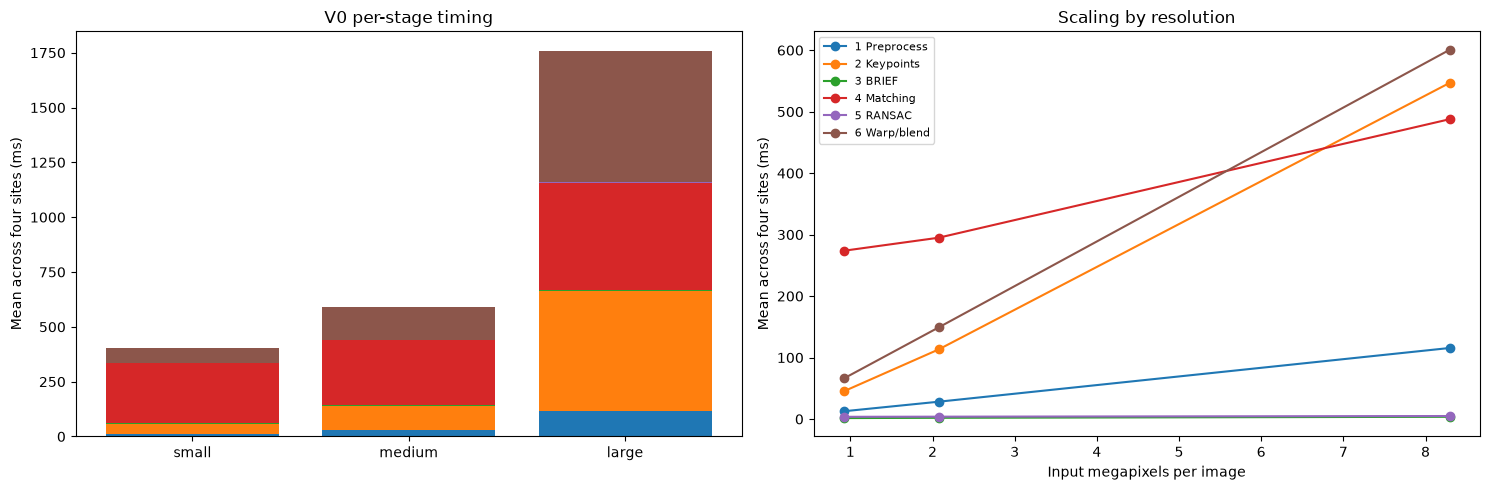

In [6]:
from report import show_timings
show_timings(summary, ROOT)

### 3.5.4 Hot Stages & Ước lượng Amdahl

**Phương pháp:**
- Chọn **cả 6 stages** cho V1 (theo kế hoạch GPU của nhóm).
- Với mỗi độ phân giải, tính:

$$p = \frac{\sum T_{\text{GPU plan}}}{T_{\text{pipeline}}} \qquad S_{\max} = \frac{1}{1 - p}$$

- Thứ hạng bottleneck được tính trực tiếp từ kết quả đo — **không giả định trước** stage nào chậm nhất.


In [7]:
from report import show_analysis
show_analysis(summary)

| Resolution | Successful sites | Two hottest stages (% total) | p (planned six stages) | 1/(1-p), compute-only bound |
|---|---|---|---|---|
| small | 4 | matching_ms: 67.9%, warp_blend_ms: 16.4% | 0.99992678 | 13657.24x |
| medium | 4 | matching_ms: 49.9%, warp_blend_ms: 25.2% | 0.99993722 | 15928.75x |
| large | 4 | warp_blend_ms: 34.1%, keypoint_ms: 31.1% | 0.99997710 | 43667.72x |

Kế hoạch V1 chuyển cả sáu stage lên GPU. Các stage đứng đầu bảng được ưu tiên profiling và tối ưu. Tổng thời gian bao gồm điều phối/cấp phát trong pipeline, loại trừ đọc/ghi ảnh và log. Khi p gần 1, giới hạn Amdahl rất nhạy với phần thời gian điều phối nhỏ; đây là giới hạn lý thuyết cho **compute-only**, không phải dự báo speedup hay số đo GPU. Chi phí truyền H2D/D2H, launch và đồng bộ phải được đo ở V1.

---

## 3.6 Bộ dữ liệu (Dataset)

**Google Drive:** [Tải dataset Nhóm 22](https://drive.google.com/drive/folders/1KEfstxQ1an5bEngfaHfXl9wIdbXWo2wF?usp=sharing) (đã kiểm tra quyền tải công khai). Gói bàn giao `Group22_Dataset.zip` bổ sung prepared + synthetic.

### Cấu trúc dữ liệu

| Thư mục | Nội dung | Số lượng |
|:---|:---|:---:|
| `dataset/raw/` | 8 ảnh gốc JPG/HEIC theo mẫu `<category>_<left\|right>.<ext>` | 8 |
| `dataset/prepared/small/` | 1280 × 720 (16:9) | 8 |
| `dataset/prepared/medium/` | 1920 × 1080 (16:9) | 8 |
| `dataset/prepared/large/` | 3840 × 2160 (16:9) | 8 |
| `dataset/synthetic/` | Synthetic pair + `H_ground_truth.txt` | 3 |
| **Tổng prepared** | | **24** |

### Quy trình chuẩn hóa
Ảnh raw → EXIF orientation → chuyển RGB → center-crop 16:9 → resize Lanczos → 3 cỡ. Ảnh gốc giữ nguyên. `manifest.json` ghi SHA256 nguồn, kích thước gốc, crop box, có/không upscale.

### Registered Sites


| Site | Địa điểm | Đặc điểm | Lý do chọn | Ánh sáng |
|---|---|---|---|---|
| site1_indoor | Phòng tự học KTX ĐHQG TPHCM | Bàn ghế, cửa sổ, tường và góc phòng | Đánh giá ghép ảnh trong nhà, nhiều mặt phẳng và tương phản ánh sáng | Ánh sáng cửa sổ và đèn trong phòng |
| site2_outdoor | Tầng 2 tòa nhà E, cơ sở 2 HCMUS | Góc hành lang, cửa và tường ít chi tiết; ảnh hướng vào trong | Đánh giá ghép các mặt phẳng kiến trúc; cần nhóm xác nhận phân loại outdoor | Ánh sáng ban ngày từ cửa và ánh sáng trong hành lang |
| site3_custom | Cửa ra vào phòng 1205 KTX ĐHQG TPHCM | Cửa, biển phòng, ô thông gió và tường phẳng | Kiểm tra mô tả đặc trưng trên cửa và các đường thẳng kiến trúc | Ánh sáng hành lang ban ngày |
| site4_challenging | Tầng 2 tòa nhà E, cơ sở 2 HCMUS | Cây xanh, cành lá và sân nhìn từ tầng 2 | Thách thức do kết cấu lá cây lặp lại và khả năng chuyển động/parallax | Ánh sáng ngoài trời ban ngày, có vùng bóng râm |

| Resolution | Images verified | Width, height | Upscaled images |
|---|---|---|---|
| small | 8 | [1280, 720] | 0 |
| medium | 8 | [1920, 1080] | 0 |
| large | 8 | [3840, 2160] | 0 |

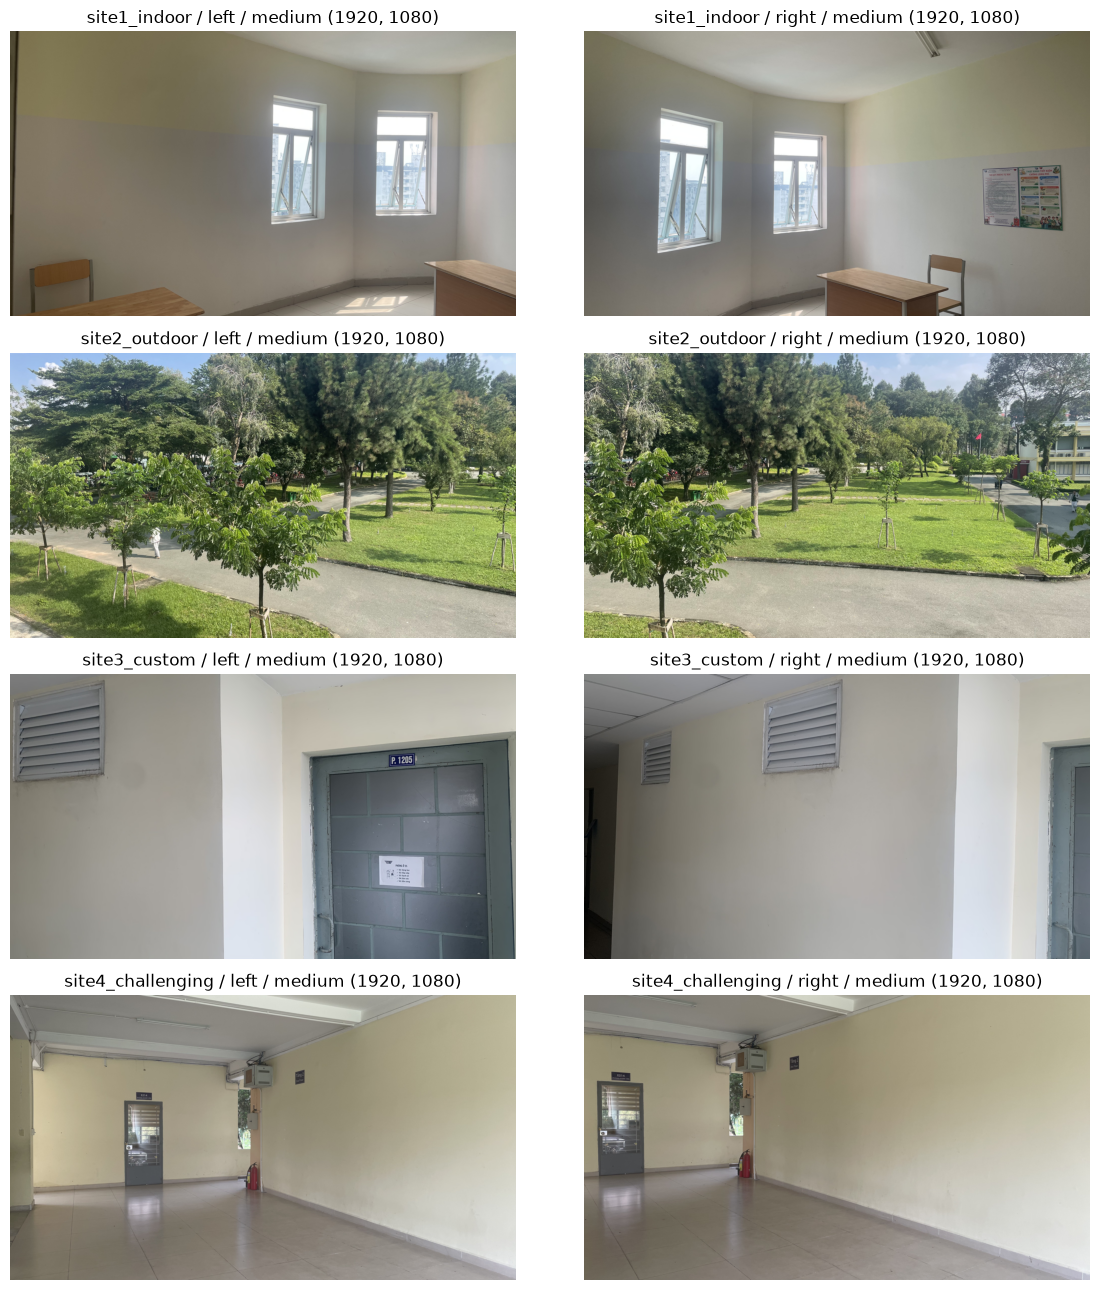

In [8]:
table(['Site', 'Địa điểm', 'Đặc điểm', 'Lý do chọn', 'Ánh sáng'], [
    [s['id'],s['location'],s['features'],s['reason'],s['lighting']] for s in team['sites']])
from report import show_dataset
show_dataset(ROOT)


---

## 3.7 Kế hoạch tăng tốc GPU

### V1 — Thread Mapping cơ bản

| Stage | Ánh xạ V1 | Ghi chú |
|:---|:---|:---|
| Grayscale + Blur | Grid 2D, mỗi thread 1 pixel; 2 pass blur | Pass ngang → pass dọc |
| FAST / NMS | Mỗi thread 1 pixel; pass NMS riêng; compact → Top-K | Output qua stream compaction |
| BRIEF | Mỗi thread 1 keypoint | Đọc patch phân tán, xử lý biên |
| BF Hamming | Mỗi thread 1 query (A→B và B→A); mutual filter | Best + second-best để tính ratio |
| RANSAC | Mỗi block 1 hypothesis; threads đánh giá inlier | Reduction trên block |
| Warp / Blend | Mỗi thread 1 pixel canvas | Exposure estimation + seam theo hàng |

### V2/V3 — Ý tưởng tối ưu nâng cao

| Kỹ thuật | Stage | Mục tiêu |
|:---|:---:|:---|
| **Shared-memory Tiling + Halos** | 1, 4 | Giảm global memory access cho blur convolution & descriptor matching |
| **Scan / Stream Compaction** | 2 | Lọc keypoints không dùng `atomicAdd` toàn cục |
| **`__popc()` intrinsic** | 4 | Đếm bit Hamming distance trên phần cứng |
| **Warp-shuffle reduction** | 5 | Đếm inlier nhanh trong RANSAC |
| **CUDA Texture Memory** | 6 | Nội suy bilinear bằng phần cứng khi warping |
| **CUDA Streams** | 1–3 | Chạy đồng thời Stages 1–3 cho ảnh A và B |
| **Kernel Fusion** | 1 | Gộp Grayscale + Blur thành 1 kernel |
| **Pinned Memory** | All | Giảm latency PCIe Host↔Device |

### Rủi ro kỹ thuật & Biện pháp

| Rủi ro | Stage | Biện pháp giảm thiểu |
|:---|:---:|:---|
| Divergence do nhánh inlier/outlier | 5 | Predicated execution; giảm if/else trong warp |
| Non-coalesced access đọc descriptor | 3 | Sắp xếp lại layout bộ nhớ |
| Canvas lớn → truy cập nguồn phân tán | 6 | Bounding box chặt; texture cache |
| Thứ tự đầu ra ảnh hưởng tái lập | 2 | Scan xác định; RNG seed cố định |
| Sai số float so với CPU | 5 | Kiểm chứng Frobenius/projection error |

**Nguyên tắc triển khai:** Chỉ chọn tối ưu sau khi đối chiếu kết quả GPU với V0, đo kernel kèm H2D/D2H bằng CUDA Events, và dùng Nsight xác định bottleneck thực tế. Các stages đứng đầu bảng profiling ở 3.5 được ưu tiên trước.

---


